# Domain-specific gene regulatory network inference

<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 50%, #0f3460 100%); color: white; padding: 1.2em 1.8em; border-radius: 10px; margin-bottom: 1em;">

<p style="margin: 0 0 0.2em 0; font-weight: 300; font-size: 0.95em; letter-spacing: 0.05em; opacity: 0.85;">BELLAICHE LAB — Institut Curie</p>
<p style="margin: 0; font-size: 0.82em; opacity: 0.7;">Adrien Leroy, Eric van Leen, Maria Balakireva, Lale Alpar, Fabian Gärtner, Rémi Pigache, Isabelle Gaugué, Stéphane Pelletier, Mehdi Ech-Chouini, Julien Delpierre, Stéphane Rigaud, Floris Bosveld, Lorette Noiret, Yohanns Bellaïche</p>
<p style="margin: 0.1em 0 0 0; font-size: 0.75em; opacity: 0.5;">April 2026</p>

</div>

With the 5-domain partition ([notebook 01](01_morphodynamic_domains.ipynb)) and the spatial transcriptome ([notebook 02](02_spatial_transcriptome_reconstruction.ipynb)), we find domain-enriched genes by tau (τ) specificity, select domain-specific transcription factors, and infer one GRN per domain from 101 GENIE3 runs (pySCENIC). Leiden communities split each network into co-regulated modules; some predictions are tested in [notebook 04](04_morphodynamics_comparison.ipynb).

**Contents**

1. [Setup](#1.-Setup)
2. [Data loading](#2.-Data-loading)
3. [Pseudobulk profiles](#3.-Pseudobulk-profiles)
4. [Tau specificity scoring](#4.-Tau-specificity-scoring)
5. [GRN inference](#5.-GRN-inference)

## 1. Setup

In [ ]:
import warnings

warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import mudata
import networkx as nx
from pathlib import Path
from skimage.filters import threshold_otsu

from vgep.grn.specificity import (
    compute_tau_scores,
    filter_tau_by_max_expression,
    compute_pseudobulk_zscores,
    find_specific_genes,
    argmax_one_hot,
)
from vgep.grn.network import (
    fetch_adjacency_file_paths,
    load_all_adjacencies,
    generate_grn_graphs_optimized,
    export_network_for_cytoscape,
    annotate_network_with_leiden_clusters,
)
from vgep.plotter import plot_tau_distribution, plot_grn

## 2. Data loading

- **Spatial transcriptome** (`.h5mu`) — bins × genes, from [notebook 02](02_spatial_transcriptome_reconstruction.ipynb)
- **scRNA-seq** (`.h5ad`) — 12,187 Seurat-annotated cells at 15 hAPF
- **Domain labels** (`.csv`) — the 5-domain partition, written by the figure framework; generate it once:

  ```bash
  python scripts/figures/generate.py --figure morphodynamic_domains
  ```
- **TF list** (`.txt`) — *Drosophila* TFs used as GENIE3 seeds
- **GENIE3 adjacencies** — 101 TF–target importance matrices from the pySCENIC CLI:

```bash
for i in {0..100}; do
    pyscenic grn epi_RNA_counts_transposed.csv TF_list.txt \
        -o epiwt15h_adjacencies_$i.tsv --num_workers 14
done
```

- **Raw UMI counts** (`.csv`) — for the pseudobulk profiles

### 2.1 Spatial transcriptome

In [ ]:
MORPHODOMAINS_ROOT = Path("..").resolve()

# Default: the Zenodo archive root (contains data/).  Override with MORPHODOMAINS_DATA.
DATA_ROOT = Path(
    os.environ.get(
        "MORPHODOMAINS_DATA",
        str(MORPHODOMAINS_ROOT.parents[1]),
    )
)

TRANSCRIPTOME_H5MU = (
    DATA_ROOT / "data/gep_results/spatial_transcriptome_output/best_transcriptome.h5mu"
)
SC_H5AD = DATA_ROOT / "data/single_cell/all_seurat_annotated_15_APF_wt.h5ad"
CLEANED_CLUSTERS = DATA_ROOT / "figures/fig_morphodynamic_domains/clustering/cleaned_clusters.csv"
CLUSTER_LABELS_5 = DATA_ROOT / "figures/fig_morphodynamic_domains/clustering/cluster_labels_5.csv"
TF_LIST_CSV = DATA_ROOT / "data/grn/TF_list.txt"
GRN_ADJACENCY_DIR = DATA_ROOT / "data/grn/adjacency"
SC_RAW_COUNTS_CSV = DATA_ROOT / "data/single_cell/all_raw_counts.csv"

transcriptome = mudata.read(TRANSCRIPTOME_H5MU)

transcriptome_df = transcriptome["st"].to_df()
obs = transcriptome["st"].obs.copy()
obs[["x", "y"]] = obs[["x", "y"]].astype(int)
transcriptome_df = pd.concat([transcriptome_df, obs], axis=1).set_index(["x", "y"])
transcriptome_df.columns = transcriptome_df.columns.str.replace("st:", "")

transcriptome

MuData object with n_obs × n_vars = 8101 × 16234
  3 modalities
    st:	491 x 4312
      obs:	'x', 'y'
      uns:	'correlations_genes_training', 'correlations_genes_validation', 'cutoff', 'morphological_marks', 'results_recap', 'training_genes', 'validation_genes'
    sc:	7610 x 4312
      layers:	'scaled_data'
    meta:	491 x 7610
      obs:	'x', 'y'
      layers:	'correlations_raw', 'mapped', 'normalized_correlation'

### 2.2 Single-cell data and cell-type annotation

GRN inference needs single-cell co-expression, so we load the scRNA-seq data and group cells by Seurat cluster. Epithelial cells mapped in [notebook 02](02_spatial_transcriptome_reconstruction.ipynb) are excluded from the pseudobulks below, keeping the reference independent of the spatial data.

In [ ]:
adata = sc.read_h5ad(SC_H5AD)

CELL_TYPE_MAP = {
    "Muscle & Trachea": [0, 9],
    "Epithelium Notum": [1, 2, 3, 4, 5, 7],
    "Epithelium Neck": [8],
    "Sensory Organ precursor": [11],
    "Unassigned": [6],
}
adata.obs["cell_type"] = "Unassigned"
for cell_type, cluster_ids in CELL_TYPE_MAP.items():
    adata.obs.loc[adata.obs["seurat_clusters"].isin(cluster_ids), "cell_type"] = (
        cell_type
    )
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")

# Mapped cells are identified from the 'mapped' layer in the 'meta' modality.
# They are excluded so the pseudobulk reference stays independent.
mapped_layer = transcriptome["meta"].layers["mapped"]
mapped_counts = np.asarray(mapped_layer.sum(axis=0)).ravel()
is_mapped = pd.Series(mapped_counts > 0, index=transcriptome["meta"].var_names)

common_cells = adata.obs_names.intersection(is_mapped.index)
adata.obs["is_mapped"] = False
adata.obs.loc[common_cells, "is_mapped"] = is_mapped.loc[common_cells].values

mask_ep = adata.obs["cell_type"] == "Epithelium Notum"
adata.obs["cell_type"] = adata.obs["cell_type"].astype(object)
adata.obs.loc[mask_ep & adata.obs["is_mapped"], "cell_type"] = (
    "Epithelium Notum (Mapped)"
)
adata.obs.loc[mask_ep & ~adata.obs["is_mapped"], "cell_type"] = (
    "Epithelium Notum (Unmapped)"
)
adata.obs.drop(columns=["is_mapped"], inplace=True)
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")

adata = adata[
    ~adata.obs["cell_type"].isin(
        ["Epithelium Notum (Mapped)", "Epithelium Notum (Unmapped)"]
    )
].copy()
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")

print("Cell types retained for pseudobulk:", adata.obs["cell_type"].unique().tolist())
print(f"Cells retained: {adata.n_obs}")

Cell types retained for pseudobulk: ['Epithelium Neck', 'Sensory Organ precursor', 'Unassigned', 'Muscle & Trachea']
Cells retained: 4577


### 2.3 Cluster labels and TF list

In [ ]:
cluster_labels_clean = pd.read_csv(CLEANED_CLUSTERS, index_col=[0, 1])
cluster_labels_5 = pd.read_csv(CLUSTER_LABELS_5, index_col=[0, 1]).iloc[:, 0]

cluster_df_5 = cluster_labels_5.to_frame(name="cluster")
cluster_df_13 = cluster_labels_clean[["13"]].rename(columns={"13": "cluster"})

tf_list = pd.read_csv(TF_LIST_CSV, header=None)[0].tolist()
print(f"TF list: {len(tf_list)} transcription factors")
print(
    f"5-MD cluster labels: {cluster_df_5.shape[0]} bins, "
    f"{cluster_df_5['cluster'].nunique()} domains"
)

TF list: 628 transcription factors
5-MD cluster labels: 389 bins, 5 domains


## 3. Pseudobulk profiles

For each non-epithelial group, counts are normalised to 10,000 UMI per cell (as the spatial bins) and averaged. These pseudobulks are background columns of the tau matrix.

In [ ]:
raw_counts = pd.read_csv(SC_RAW_COUNTS_CSV, index_col=0).T  # cells × genes

# Restrict to the genes present in the spatial transcriptome
common_genes = raw_counts.columns.intersection(transcriptome_df.columns)
raw_counts = raw_counts.loc[:, common_genes]
print(f"Genes shared with spatial transcriptome: {len(common_genes)}")

# Normalise to target sum 10 000
sc_sums = raw_counts.sum(axis=1).clip(lower=1)
raw_counts = raw_counts.div(sc_sums, axis=0).multiply(10_000)

# Pseudobulk: mean per cell-type group
common_cells = adata.obs_names.intersection(raw_counts.index)
raw_counts_filt = raw_counts.loc[common_cells]
groups = adata.obs.loc[common_cells, "cell_type"]
sc_pseudobulk = raw_counts_filt.groupby(groups, observed=True).mean().T

# Rename columns to short labels used in the tau reference matrix
SC_GROUP_RENAME = {
    "Epithelium Notum (Unmapped)": "Epithelium Notum (Unmapped)",
    "Sensory Organ precursor": "SOP",
    "Epithelium Neck": "Epithelium Neck",
    "Muscle & Trachea": "Muscle & Trachea",
    "Unassigned": "Unassigned",
}
sc_group_expression = sc_pseudobulk.rename(columns=SC_GROUP_RENAME)[
    [
        v
        for v in SC_GROUP_RENAME.values()
        if v in sc_pseudobulk.rename(columns=SC_GROUP_RENAME).columns
    ]
]
print(
    f"Pseudobulk matrix: {sc_group_expression.shape[0]} genes × {sc_group_expression.shape[1]} groups"
)
sc_group_expression.head()

Genes shared with spatial transcriptome: 4312
Pseudobulk matrix: 4312 genes × 4 groups


cell_type,SOP,Epithelium Neck,Muscle & Trachea,Unassigned
Parp,1.765341,0.927818,1.083125,1.327521
Alg-2,1.851189,1.230177,0.902761,1.205541
Tim17b,4.385428,3.028924,4.836490,3.388852
CG41128,2.004358,1.250061,2.420314,1.275249
CG41099,0.515983,0.300033,0.278074,0.498169


## 4. Tau specificity scoring

### 4.1 Build unified reference matrix

τ depends on the reference matrix. To avoid calling genes expressed outside the notum (e.g. the neck marker *Dfd*), the five domains are joined by a background column (bins outside the partition) and pseudobulks of non-epithelial cell types (SOP, Epithelium Neck, Muscle & Trachea, Unassigned).

In [ ]:
# Add a background cluster: bins in the transcriptome but outside the 5-MD domains
outside_coords = transcriptome_df.index.difference(cluster_df_5.index)
outside_id_5 = int(cluster_df_5["cluster"].max()) + 1

cluster_df_5_ext = pd.concat(
    [
        cluster_df_5,
        pd.DataFrame({"cluster": outside_id_5}, index=outside_coords),
    ]
)
cluster_df_5_ext = cluster_df_5_ext.loc[transcriptome_df.index]

print(f"Background bins (outside 5-MD): {len(outside_coords)}")
print(f"Extended cluster IDs: {sorted(cluster_df_5_ext['cluster'].unique())}")

Background bins (outside 5-MD): 104
Extended cluster IDs: [0, 1, 2, 3, 4, 5]


In [ ]:
# Tau scores on spatial domains only (step 1)
tau_scores_5_spatial, avg_expr_5_spatial = compute_tau_scores(
    cluster_df_5_ext["cluster"], transcriptome_df
)

# Combine with SC pseudobulks to form the full reference matrix
sc_aligned = sc_group_expression.reindex(avg_expr_5_spatial.index).fillna(0)
combined_expr_5 = pd.concat([avg_expr_5_spatial, sc_aligned], axis=1)

print("Unified reference matrix shape:", combined_expr_5.shape)
print("Columns:", combined_expr_5.columns.tolist())

Unified reference matrix shape: (4312, 10)
Columns: [0, 1, 2, 3, 4, 5, 'SOP', 'Epithelium Neck', 'Muscle & Trachea', 'Unassigned']


### 4.2 Compute tau scores and filter by max-expression domain

`filter_tau_by_max_expression` keeps genes whose maximum lies in one of the five domains.

In [ ]:
primary_clusters_5 = sorted(
    [c for c in avg_expr_5_spatial.columns if c != outside_id_5]
)

tau_scores_5 = filter_tau_by_max_expression(
    tau_scores_5_spatial,
    combined_expr_5,
    primary_clusters_5,
)
print(f"Genes retained: {len(tau_scores_5)} / {len(tau_scores_5_spatial)}")

# Z-score the unified matrix (log1p then StandardScaler across conditions)
z_bin_mean_5 = compute_pseudobulk_zscores(combined_expr_5)

Genes retained: 994 / 4312


### 4.3 Otsu threshold and domain-specific gene set

τ is bimodal; Otsu's method separates broadly expressed from domain-specific genes without manual tuning.

Otsu threshold: 0.3631
Domain-specific genes (τ > 0.363): 259


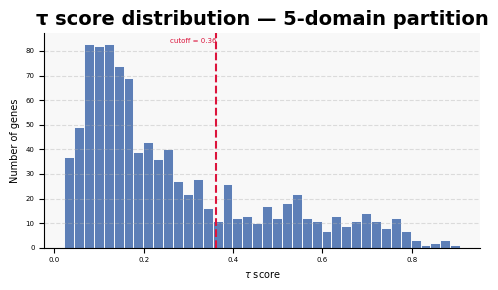

In [ ]:
otsu_thresh = threshold_otsu(tau_scores_5.values)
print(f"Otsu threshold: {otsu_thresh:.4f}")

specific_genes_5, _ = find_specific_genes(tau_scores_5, threshold=otsu_thresh)
print(f"Domain-specific genes (τ > {otsu_thresh:.3f}): {specific_genes_5.sum()}")

plot_tau_distribution(
    tau_scores_5,
    cutoff=otsu_thresh,
    title="τ score distribution — 5-domain partition",
    bins=40,
    fig_size=(5, 3),
)
plt.show()

### 4.4 Domain-specific TFs

Domain-specific genes that are TFs seed the GRN inference; each TF is assigned to its domain of maximal expression.

In [ ]:
# Filter to TFs only
specific_tfs_5 = specific_genes_5[specific_genes_5].index.intersection(tf_list)
print(f"Domain-specific TFs: {len(specific_tfs_5)}")

# One-hot assignment: each gene → domain where average expression is maximal
avg_expr_5_filtered = avg_expr_5_spatial.loc[specific_genes_5[specific_genes_5].index]
combinations_5 = argmax_one_hot(avg_expr_5_filtered)
combinations_df_5 = pd.DataFrame(
    combinations_5,
    index=avg_expr_5_filtered.index,
    columns=avg_expr_5_filtered.columns,
).drop(columns=[outside_id_5], errors="ignore")

# Restrict to TFs
combinations_df_5 = combinations_df_5.loc[combinations_df_5.index.isin(tf_list)]

print("TFs per domain:")
for col in combinations_df_5.columns:
    tfs = combinations_df_5.index[combinations_df_5[col] == 1].tolist()
    print(f"  5-MD{col+1}: {tfs}")

Domain-specific TFs: 38
TFs per domain:
  5-MD1: ['grn', 'E5', 'ems', 'dysf', 'Dr', 'al', 'ush']
  5-MD2: ['trh', 'h', 'Doc3', 'Doc2', 'Doc1', 'mirr', 'dpn', 'inv', 'en', 'Dll', 'bi', 'disco-r', 'disco', 'esg', 'dac']
  5-MD3: ['NK7.1', 'CG42741']
  5-MD4: ['Awh', 'ara', 'caup', 'pdm3', 'ovo', 'salr', 'salm', 'elB', 'tsh', 'tio']
  5-MD5: ['sr', 'klu', 'toe', 'eyg']


### 4.5 Expression heatmap

Z-scored expression of the domain-specific TFs across the five domains, hierarchically clustered.

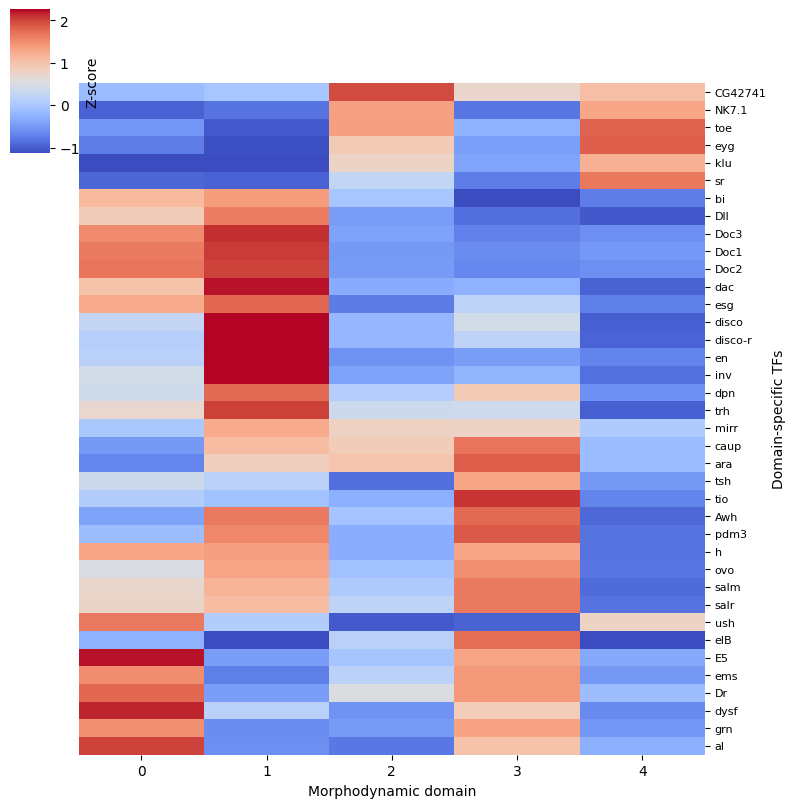

In [11]:
specific_tfs = specific_genes_5[specific_genes_5].index.intersection(tf_list)
specific_tfs = specific_tfs.intersection(z_bin_mean_5.index)

cluster_means = z_bin_mean_5.loc[specific_tfs, [0, 1, 2, 3, 4]]
gene_order = cluster_means.idxmax(axis=1).sort_values().index

g = sns.clustermap(
    cluster_means.loc[gene_order],
    row_cluster=True,
    col_cluster=False,
    dendrogram_ratio=0.1,
    cmap="coolwarm",
    robust=True,
    figsize=(8, 8),
    cbar_kws={"label": "Z-score"},
    yticklabels=True,
)
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.set_xlabel("Morphodynamic domain")
g.ax_heatmap.set_ylabel("Domain-specific TFs")
g.ax_heatmap.tick_params(axis="y", labelsize=8)
plt.show()

## 5. GRN inference

GENIE3 predicts TF–target links from non-linear co-expression in the scRNA-seq data. An edge is kept only if it appears in ≥ 80 % of the 101 runs; each TF keeps its top 10 targets by mean importance.

### 5.1 Load adjacency matrices

In [ ]:
# Each file in GRN_ADJACENCY_DIR is one GENIE3 run (CSV: TF, target, importance)
adjacency_files = fetch_adjacency_file_paths(folder_path=GRN_ADJACENCY_DIR)
combined_adjacencies = load_all_adjacencies(adjacency_files)

print(f"GENIE3 runs loaded: {len(adjacency_files)}")
print(f"Total TF–target pairs (before filtering): {len(combined_adjacencies)}")

Loading adjacency files: 100%|██████████| 101/101 [01:15<00:00,  1.34it/s]


GENIE3 runs loaded: 101
Total TF–target pairs (before filtering): 250053411


### 5.2 Build consensus GRNs

In [ ]:
# One NetworkX graph per domain
# min_occurrence_fraction=0.8 → edge must appear in ≥ 80 % of the 101 runs
# n_top=10 → keep top 10 targets per TF (ranked by mean importance score)
grn_graphs_5 = generate_grn_graphs_optimized(
    combinations_df=combinations_df_5,
    combined_adjacencies=combined_adjacencies,
    tf_list=tf_list,
    min_occurrence_fraction=0.8,
    n_top=10,
    z_cluster_means=z_bin_mean_5,
)

for domain, G in grn_graphs_5.items():
    types = [d.get("node_type") for _, d in G.nodes(data=True)]
    n_tfs = sum(1 for t in types if t == "tf")
    n_targets = sum(1 for t in types if t == "target")
    print(
        f"  5-MD{domain+1}: {n_tfs} TFs, {n_targets} targets, "
        f"{G.number_of_edges()} edges"
    )

Building network for cluster Cluster_4: 100%|██████████| 4/4 [01:25<00:00, 21.50s/it]

  5-MD1: 17 TFs, 40 targets, 74 edges
  5-MD2: 35 TFs, 68 targets, 160 edges
  5-MD3: 3 TFs, 19 targets, 22 edges
  5-MD4: 23 TFs, 46 targets, 105 edges
  5-MD5: 6 TFs, 24 targets, 42 edges


### 5.3 Leiden community detection

Leiden (`RBConfigurationVertexPartition`, resolution 1.0) splits each domain's GRN into co-regulated modules.

In [ ]:
for domain, G in grn_graphs_5.items():
    if G.number_of_nodes() < 3:
        print(f"  5-MD{domain+1}: skipped (graph too small)")
        continue
    annotate_network_with_leiden_clusters(G, resolution=1.0)
    modules = {
        d.get("cluster") for _, d in G.nodes(data=True) if d.get("cluster") is not None
    }
    print(f"  5-MD{domain+1}: {len(modules)} Leiden module(s)")

  5-MD1: 5 Leiden module(s)
  5-MD2: 8 Leiden module(s)
  5-MD3: 2 Leiden module(s)
  5-MD4: 6 Leiden module(s)
  5-MD5: 3 Leiden module(s)


### 5.4 Network visualisation and export

In [ ]:
CYTOSCAPE_DIR = MORPHODOMAINS_ROOT / "output/cytoscape_exports"
CYTOSCAPE_DIR.mkdir(parents=True, exist_ok=True)

for domain, G in grn_graphs_5.items():
    export_network_for_cytoscape(
        G,
        CYTOSCAPE_DIR / "5_domains",
        f"grn_domain_{domain+1}",
        tau_scores=tau_scores_5,
    )

print(f"Networks exported to {CYTOSCAPE_DIR / '5_domains'}")

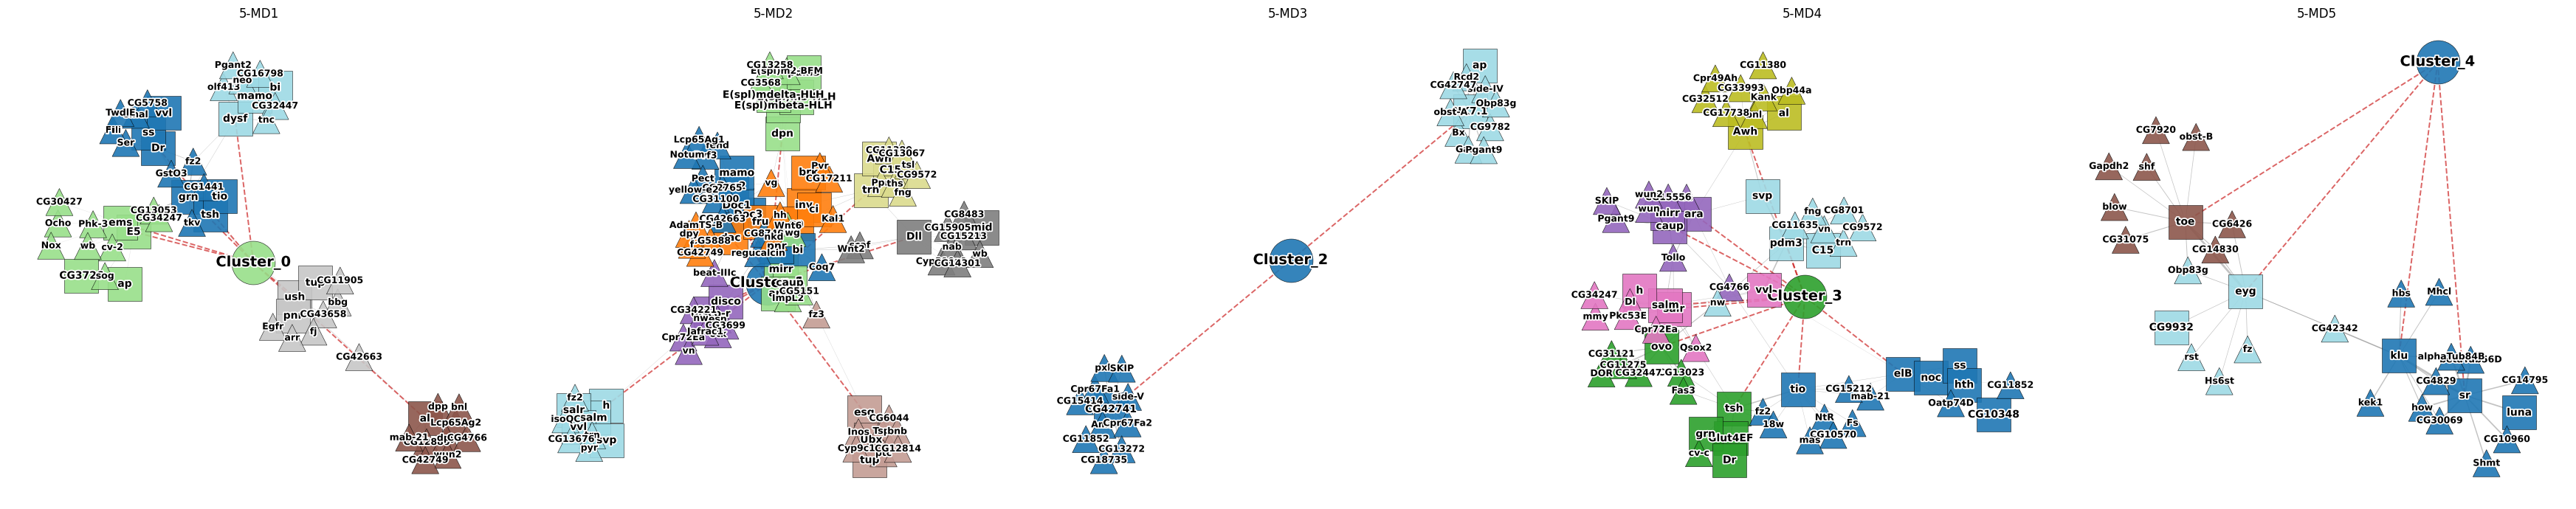

In [ ]:
# Five full GRNs in one figure. Node shape = role (TF=square, target=triangle);
# node colour = Leiden module. Labels are centred on their node with a white
# halo so target names stay readable even when they overflow the glyph.
n_domains = len(grn_graphs_5)
fig, axes = plt.subplots(1, n_domains, figsize=(7 * n_domains, 7))
if n_domains == 1:
    axes = [axes]
for ax, (domain, G) in zip(axes, sorted(grn_graphs_5.items())):
    plot_grn(
        G,
        ax=ax,
        title=f"5-MD{domain + 1}",
        color_by="leiden",
        label="all",
    )
plt.tight_layout()
plt.show()